In [ ]:
import os
os.chdir(os.path.expandvars("/scratch/vp91/$USER/intro-to-cuda"))

# CUDA Events


> **Overview**
>
> 
>  * **Time:** 30 min
> 
>  1. Learn about CUDA events and their usage.
>  1. Understand how to measure elapsed time using CUDA events.

CUDA events are a powerful feature that allows you to measure the time taken by operations on the GPU.
They can be used to synchronize between different streams and to profile the performance of your CUDA
applications. Events are lightweight and provide a way to track the completion of operations without
blocking the CPU.

## CUDA Event Basics


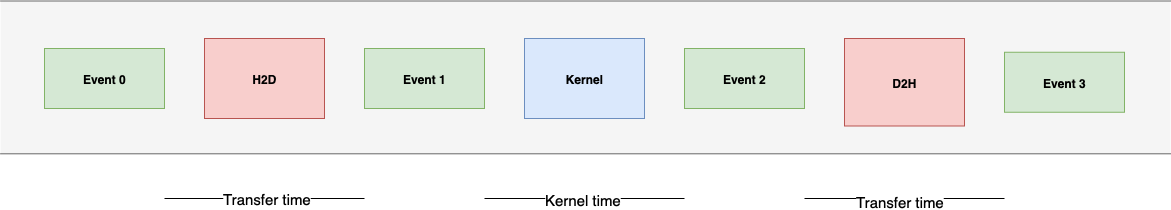

CUDA events are used to mark points in time in your CUDA application. They can be created, recorded, and
queried to determine when certain operations have completed. Events can be used to measure the elapsed time
between two points in your code, which is useful for performance profiling. CUDA events are created using
the `cudaEventCreate` function, and you can record an event using `cudaEventRecord`.

```cpp
cudaEvent_t start, stop;
cudaEventCreate(&start);
cudaEventCreate(&stop);

// Record the start event
cudaEventRecord(start, 0);

// Perform some GPU operations here

// Record the stop event
cudaEventRecord(stop, 0);

// Wait for the stop event to complete
cudaEventSynchronize(stop);

float milliseconds = 0;
cudaEventElapsedTime(&milliseconds, start, stop);
printf("Elapsed time: %f ms\n", milliseconds);
```

## Cross stream Synchronization


CUDA events can also be used for cross-stream synchronization. When you record an event in one stream,
it can be waited on in another stream. This allows you to synchronize operations across different streams without blocking the CPU.

```cpp
cudaStream_t stream1, stream2;
cudaStreamCreate(&stream1);
cudaStreamCreate(&stream2);

cudaEvent_t event;
cudaEventCreate(&event);

// Perform the producer operation in stream1
kernel1<<<blocks, threads, 0, stream1>>>(...);

// Capture completion of the producer, then make stream2 wait for it
cudaEventRecord(event, stream1);

// Wait for the event in stream2
cudaStreamWaitEvent(stream2, event, 0);

// Perform some operations in stream2 that depend on the completion of stream1
kernel2<<<blocks, threads, 0, stream2>>>(...);

// Wait before releasing resources used by the consumer
cudaStreamSynchronize(stream2);

// Cleanup
cudaEventDestroy(event);
cudaStreamDestroy(stream1);
cudaStreamDestroy(stream2);
```

> **Explanation**
>
> 
>  `cudaStreamWaitEvent` is used to make a stream wait for an event recorded in another stream.

## Timing events across streams


When timing events across streams, you can record events in one stream and then wait for those events
in another stream. This allows you to measure the time taken by operations in different streams without
blocking the CPU.

```cpp
cudaStream_t stream1, stream2;
cudaStreamCreate(&stream1);
cudaStreamCreate(&stream2);

cudaEvent_t start, stop, producerDone;
cudaEventCreate(&start);
cudaEventCreate(&stop);
cudaEventCreate(&producerDone);

// Record the start event in stream1
cudaEventRecord(start, stream1);

// Perform some operations in stream1
kernel1<<<blocks, threads, 0, stream1>>>(...);

// Make the stop marker depend on completion of kernel1
cudaEventRecord(producerDone, stream1);
cudaStreamWaitEvent(stream2, producerDone, 0);
cudaEventRecord(stop, stream2);

// This host-side wait ensures both timestamps are available
cudaEventSynchronize(stop);

float milliseconds = 0;
cudaEventElapsedTime(&milliseconds, start, stop);
printf("Elapsed time across streams: %f ms\n", milliseconds);

cudaEventDestroy(start);
cudaEventDestroy(stop);
cudaEventDestroy(producerDone);
cudaStreamDestroy(stream1);
cudaStreamDestroy(stream2);
```

> **Important**
>
> 1. You cannot use an event recorded in one stream to measure the execution time of operations that occur in another stream unless you enforce proper synchronization.
> 1. If streams are non-blocking and concurrent, incorrect usage may lead to race conditions or invalid timings.

> **Key Points**
>
> 
>  1. CUDA events are used to measure elapsed time and synchronize operations across streams.
>  1. Events can be created, recorded, and queried to determine the completion of operations.
>  1. Cross-stream synchronization is achieved using `cudaStreamWaitEvent`.
>  1. Timing events across streams requires careful synchronization to ensure accurate measurements.
>  1. Events are lightweight and do not block the CPU, making them suitable for performance profiling.

## Event ordering in these examples

The notebook corrects two ordering issues in the RST examples: the cross-stream dependency is recorded **after** the producer kernel, and the cross-stream stop event waits for producer completion. An event captures work already submitted to its stream; later submissions are not included. See [NVIDIA event documentation](https://docs.nvidia.com/cuda/cuda-runtime-api/group__CUDART__EVENT.html).

`cudaStreamWaitEvent` queues a device-side dependency; `cudaEventSynchronize` waits on the CPU. Recording events can be asynchronous, but explicit host synchronization blocks until completion.

The snippets above illustrate API ordering and contain omitted kernels and launch parameters (`...`), so they are not standalone programs. The executable example below is complete.

## Exercise 08: CUDA Events
**Time: 20 min**

1. Run [exercises/08-events/vector-add-async.cu](../exercises/08-events/vector-add-async.cu) and check the output.
2. Do all the kernels have the same execution time?

Use a notebook kernel on an allocated GPU node with CUDA loaded and CMake and the CUDA toolkit available. The program runs ten vector additions using four streams, reports event timing for each iteration, and verifies the results.

### Compile the program

In [ ]:
!cmake -S exercises -B exercises/build -DCMAKE_BUILD_TYPE=Release -DEXERCISES_EXTRA_SOURCES=""
!cmake --build exercises/build --parallel 4 --target ex-08-events-vector-add-async


### Run and check the output

Check that verification reports `PASSED`. Rerun this cell several times to compare timings.

In [ ]:
!./exercises/build/ex-08-events-vector-add-async

### Interpret what is being timed

The supplied program records its start event **before the host-to-device copies** and its stop event **after the device-to-host copy**, in the same stream. Each printed time therefore covers the iteration's transfers and kernel execution, including any gaps between those event markers. It does not isolate the kernel.

1. Record the smallest and largest reported iteration times. Are they identical across runs?
2. To answer the kernel-only question, move the start event to immediately before `vectorAdd2D<<<...>>>`, after both input copies. Move the stop event to immediately after the kernel launch, before the output copy. Keep both events in `streams[stream_id]`.
3. Recompile and rerun. How do the kernel-only timings compare with the original transfer-plus-kernel timings?
4. Does using the same kernel and input size guarantee identical measured times when other streams are active?

### Observations

| Run | Measurement | Smallest time (ms) | Largest time (ms) | Verification |
| --- | --- | --- | --- | --- |
| Original | Transfers + kernel | | | |
| Modified | Kernel only | | | |

Record the timing variation and explain the event placement used for each measurement.